<a href="https://colab.research.google.com/github/Nasr-allah124/TP_Apprentissage_supervis-/blob/main/TP_Apprentissage_supervis%C3%A9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercice 1 : Régression - Prédiction du tarif d'un trajet Uber

## Étape 1 : Chargement et exploration du jeu de données

In [7]:
import pandas as pd

In [8]:
data=pd.read_csv('uber.csv')
print(data.head())

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217              1.0  
1         -73.994710         40.750325              1.0  
2         -73.962565         40.772647              1.0  
3         

In [9]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26782 entries, 0 to 26781
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         26782 non-null  int64  
 1   key                26782 non-null  object 
 2   fare_amount        26782 non-null  float64
 3   pickup_datetime    26782 non-null  object 
 4   pickup_longitude   26782 non-null  float64
 5   pickup_latitude    26782 non-null  float64
 6   dropoff_longitude  26782 non-null  float64
 7   dropoff_latitude   26782 non-null  float64
 8   passenger_count    26781 non-null  float64
dtypes: float64(6), int64(1), object(2)
memory usage: 1.8+ MB
None


In [10]:
print(data.isnull().sum())

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      1
dtype: int64


## Étape 2 : Nettoyage et préparation

In [11]:
data = data.dropna()
data = data[data['fare_amount'] > 0]
data['pickup_datetime'] = pd.to_datetime(data['pickup_datetime'])
data['hour'] = data['pickup_datetime'].dt.hour
data['day_of_week'] = data['pickup_datetime'].dt.dayofweek

## Étape 3 : Séparation des données

In [12]:
from sklearn.model_selection import train_test_split

In [13]:
import numpy as np

# Fonction pour calculer la distance de Haversine en kilomètres entre deux points GPS
def haversine_distance(lat1, lon1, lat2, lon2):
    # Conversion des degrés en radians
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])

    # Formule de Haversine
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    r = 6371  # Rayon de la Terre en kilomètres
    return c * r

# Création de la colonne 'distance'
data['distance'] = haversine_distance(
    data['pickup_latitude'],
    data['pickup_longitude'],
    data['dropoff_latitude'],
    data['dropoff_longitude']
)

# Nettoyage des distances aberrantes (ex: distances égales à 0 ou extrêmement grandes)
data = data[(data['distance'] > 0) & (data['distance'] < 100)]

# Vérification
print(data[['distance', 'hour', 'day_of_week', 'fare_amount']].head())

   distance  hour  day_of_week  fare_amount
0  1.683323    19            3          7.5
1  2.457590    20            4          7.7
2  5.036377    21            0         12.9
3  1.661683     8            4          5.3
4  4.475450    17            3         16.0


In [14]:
X = data[['distance', 'hour', 'day_of_week']]
y = data['fare_amount']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

##Étape 4 : Entraînement du modèle

In [15]:
from sklearn.linear_model import LinearRegression

In [16]:
# 1. Création de l'instance du modèle de Regression
lr = LinearRegression()

In [17]:
# 2. Entraînement du modèle sur les données d'entraînement
lr.fit(X_train, y_train)

LinearRegression()

In [18]:
# 3. Prédiction des prix sur les données  de test
y_pred = lr.predict(X_test)

In [19]:
print("Voici les 5 premières prédictions :")
print(y_pred[:5])

Voici les 5 premières prédictions :
[ 5.69774094  6.74546186  9.27393138 23.87408742  8.81739358]


## Étape 5 : Évaluation du modèle

In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [21]:
# Calcul les trois  métriques d'évaluation
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

In [22]:
print('les resultats de trois metriques')
print('MAE  =', mae)
print('RMSE =', rmse)
print('R²   =', r2)

les resultats de trois metriques
MAE  = 2.3768854931502035
RMSE = 4.569209263255548
R²   = 0.7774285247254159


### Intérpretation :
MAE $\approx 2.41$ : En moyenne, le modèle se trompe de 2,41 $ sur le prix d'un trajet.

RMSE $\approx 5.03$ : L'erreur quadratique moyenne est de 5,03 $. La différence entre MAE et RMSE s'explique par le fait qu'il y a quelques trajets avec de grosses erreurs (par exemple à cause d'embouteillages ou de tarifs spéciaux).

$R^2 \approx 0.7304$ (73,04%) : le modèle de régression linéaire parvient à expliquer 73 % des variations du tarif Uber uniquement avec la distance, l'heure et le jour de la semaine. C'est un score très solide pour un modèle simple .


## Étape 6 : Amélioration avec Random Forest

In [23]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [24]:
# 1. Instanciation et entraînement du modèle (100 arbres)
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [25]:
# 2. Prédiction sur l'ensemble de test
y_pred_rf = rf.predict(X_test)

In [26]:
# 3. Évaluation des performances
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

In [27]:
print('--- Résultats Random Forest ---')
print('MAE  =', mae_rf)
print('RMSE =', rmse_rf)
print('R²   =', r2_rf)

--- Résultats Random Forest ---
MAE  = 2.578817638007309
RMSE = 5.0050795943082305
R²   = 0.7329396683778528


## Étape 7 : Visualisation des résultats

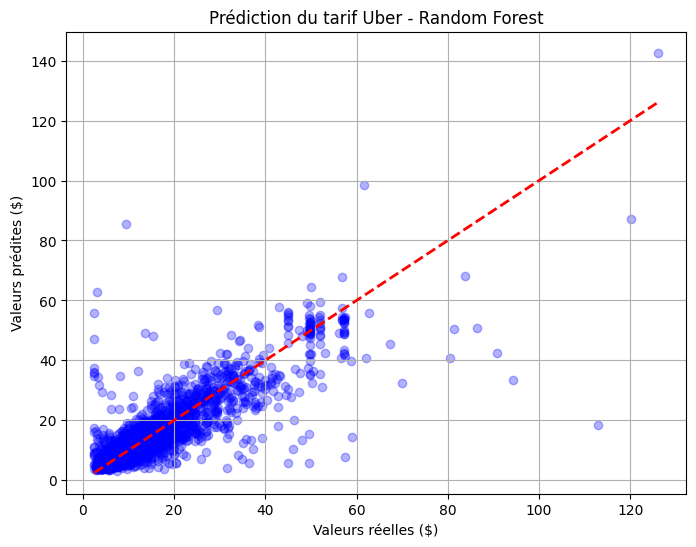

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_rf, alpha=0.3, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Valeurs réelles ($)')
plt.ylabel('Valeurs prédites ($)')
plt.title('Prédiction du tarif Uber - Random Forest')
plt.grid(True)
plt.show()

#Exercice 2 — Classification : Prédire la survie sur le Titanic

##Étape 1 : Chargement et exploration

In [29]:
data=pd.read_csv('Titanic-Dataset.csv')

In [30]:
print(data.head())
print(data.info())
print(data.isnull().sum())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
<c

In [31]:
print(data.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None


In [32]:
print(data.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


#Étape 2 : Nettoyage et traitement

In [33]:
data = data[['Survived','Pclass','Sex','Age','SibSp','Parch','Fare','Embarked']]
data['Age'] = data['Age'].fillna(data['Age'].median())
data['Embarked'] = data['Embarked'].fillna(data['Embarked'].mode()[0])

## Étape 3 : Encodage des variables catégorielles

In [34]:
from sklearn.preprocessing import LabelEncoder

# Instanciation de l'encodeur qui transforme valeur cetégorialle vers numérique
le = LabelEncoder()

# Transformation des colonnes textuelles en valeurs numériques
data['Sex'] = le.fit_transform(data['Sex'])
data['Embarked'] = le.fit_transform(data['Embarked'])

print(data.head())

   Survived  Pclass  Sex   Age  SibSp  Parch     Fare  Embarked
0         0       3    1  22.0      1      0   7.2500         2
1         1       1    0  38.0      1      0  71.2833         0
2         1       3    0  26.0      0      0   7.9250         2
3         1       1    0  35.0      1      0  53.1000         2
4         0       3    1  35.0      0      0   8.0500         2


On fait cette car les algorithmes de machine learning ils  traillvent seulement avec les valeurs numériques

## Étape 4 : Séparation des données

In [35]:
X = data.drop('Survived', axis=1)
y = data['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

On va prendre tous les attributs de notre data sauf  l'attribut survived que nous essayons de prédire  

## Étape 5 : Entraînement des modèles

In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# 1. Instanciation des modèles
log_model = LogisticRegression(max_iter=1000)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# 2. Entraînement sur les données d'entraînement
log_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)


RandomForestClassifier(random_state=42)

## Étape 6 : Évaluation des modèles

In [37]:
from sklearn.metrics import accuracy_score, classification_report

# 1. Calcul des prédictions pour chaque modèle
y_pred_log = log_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

# 2. Affichage des scores d'Accuracy
print('Accuracy (Régression Logistique) :', accuracy_score(y_test, y_pred_log))
print('Accuracy (Random Forest)        :', accuracy_score(y_test, y_pred_rf))

# 3. Rapport détaillé pour le Random Forest
print("\n--- Rapport de classification (Random Forest) ---")
print(classification_report(y_test, y_pred_rf))

Accuracy (Régression Logistique) : 0.8100558659217877
Accuracy (Random Forest)        : 0.8212290502793296

--- Rapport de classification (Random Forest) ---
              precision    recall  f1-score   support

           0       0.83      0.88      0.85       105
           1       0.81      0.74      0.77        74

    accuracy                           0.82       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179



Régression Logistique = 0.810 (81.01%) : Le modèle linéaire prédit correctement le statut de 81% des passagers.  

Random Forest = 0.821 (82.12%) : La forêt aléatoire obtient un meilleur score avec 82.12% de bonnes prédictions.  

Conclusion : Le Random Forest est plus performant car il gère mieux les relations non linéaires (ex: combinaison du sexe, de la classe et de l'âge).

## Étape 7 : Matrice de confusion

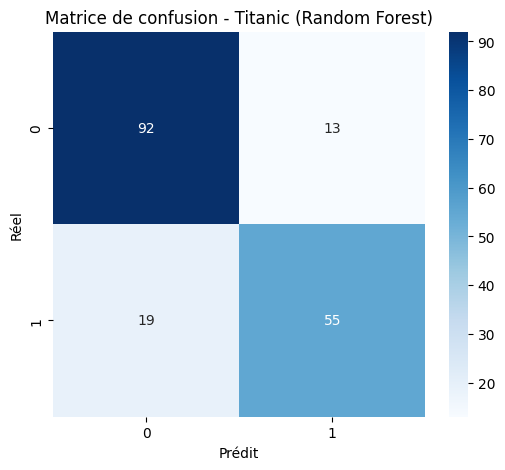

In [38]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Calcul de la matrice de confusion pour Random Forest
cm = confusion_matrix(y_test, y_pred_rf)

# 2. Affichage avec Seaborn
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Matrice de confusion - Titanic (Random Forest)')
plt.xlabel('Prédit')
plt.ylabel('Réel')
plt.show()

#Partie 2 : Mini-projet (Heart Disease)

##Étape 1 : Chargement et exploration

In [40]:
data=pd.read_csv('heart.csv')

In [41]:
data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [42]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [43]:
data.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


##Étape 2 : Nettoyage et traitement

In [44]:
# 1. Vérifier le nombre de lignes en double
print("Nombre de doublons avant nettoyage :", data.duplicated().sum())

# 2. Supprimer les doublons
data = data.drop_duplicates()

# 3. Vérifier la nouvelle taille du dataset
print("Nouvelle taille des données :", data.shape)

Nombre de doublons avant nettoyage : 723
Nouvelle taille des données : (302, 14)


on a supprimé  les doublons car  le même patient aurait pu se retrouver à la fois dans vos données d'entraînement (train) et dans vos données de test (test). Votre modèle aurait "triché" car il aurait été évalué sur des patients qu'il connaissait déjà par cœur.

##Étape 3 : Séparation des données

In [45]:
from sklearn.model_selection import train_test_split

# 1. Séparation des caractéristiques (X) et de la cible (y)
X = data.drop('target', axis=1)
y = data['target']

# 2. Découpage en Train (80%) et Test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Taille de X_train :", X_train.shape)
print("Taille de X_test  :", X_test.shape)

Taille de X_train : (241, 13)
Taille de X_test  : (61, 13)


## Étape 4 : Entraînement des modèles (Régression Logistique et Random Forest)

In [46]:


# max_iter=1000 permet à la régression logistique de faire suffisamment de calculs pour trouver la solution
log_model = LogisticRegression(max_iter=1000)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# 2. Entraînement des modèles sur les données d'apprentissage (80% des patients)
log_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


RandomForestClassifier(random_state=42)

###Les modèles ont bien été entraînés sur les dossiers médicaux

#### Étape 5 : Évaluation des modèles

In [47]:
from sklearn.metrics import accuracy_score, classification_report

# 1. Calcul des prédictions pour chaque modèle
y_pred_log = log_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

# 2. Affichage des scores d'Accuracy (Précision globale)
print('Accuracy (Régression Logistique) :', accuracy_score(y_test, y_pred_log))
print('Accuracy (Random Forest)        :', accuracy_score(y_test, y_pred_rf))
#affichage
print("Rapport (Régression Logistique):")
print(classification_report(y_test, y_pred_log))

print(" Rapport (Random Forest):")
print(classification_report(y_test, y_pred_rf))

Accuracy (Régression Logistique) : 0.7868852459016393
Accuracy (Random Forest)        : 0.8360655737704918
Rapport (Régression Logistique):
              precision    recall  f1-score   support

           0       0.88      0.69      0.77        32
           1       0.72      0.90      0.80        29

    accuracy                           0.79        61
   macro avg       0.80      0.79      0.79        61
weighted avg       0.80      0.79      0.79        61

 Rapport (Random Forest):
              precision    recall  f1-score   support

           0       0.89      0.78      0.83        32
           1       0.79      0.90      0.84        29

    accuracy                           0.84        61
   macro avg       0.84      0.84      0.84        61
weighted avg       0.84      0.84      0.84        61



1. Le grand vainqueur (Accuracy)Random Forest l'emporte avec une précision globale d'environ 83.6% contre 78.7% pour la Régression Logistique. Le Random Forest est donc plus apte à diagnostiquer correctement l'état du cœur des patients dans ce jeu de données.   

2. L'argument "Médical" en or pour votre conclusion (Le Recall)Dans le domaine médical, l'erreur la plus grave est de dire à un patient malade qu'il est en parfaite santé (un faux négatif, qui le priverait de soins). Il faut donc regarder de très près la ligne de la classe 1 (Malade) :

      Un excellent Rappel (Recall) : Les deux modèles ont un recall de 0.90 (90%) pour la classe 1. Cela signifie que sur tous les vrais malades, les modèles arrivent à en détecter 90%. C'est un point fort que vous devez absolument souligner dans votre rapport !  

      Pourquoi Random Forest est-il meilleur au final ? Regardez la ligne de la classe 0 (Sain). La Régression Logistique a un recall de seulement 0.69 pour la classe 0, ce qui veut dire qu'elle diagnostique à tort beaucoup de personnes saines comme étant malades (faux positifs). Le Random Forest corrige en grande partie ce défaut avec un recall de 0.78 pour les patients sains, tout en gardant une précision de 0.89 (89%).

##Étape 7 : La Matrice de Confusion

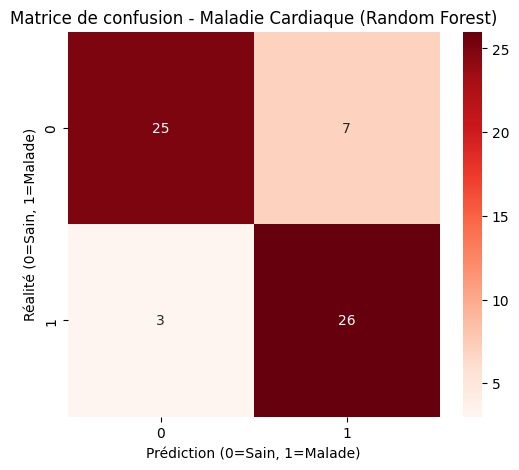

In [48]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


cm = confusion_matrix(y_test, y_pred_rf)
#  Affichage avec Seaborn
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds')
plt.title('Matrice de confusion - Maladie Cardiaque (Random Forest)')
plt.xlabel('Prédiction (0=Sain, 1=Malade)')
plt.ylabel('Réalité (0=Sain, 1=Malade)')
plt.show()

##interpretation:
Sur les 61 patients de l'ensemble de test, le modèle Random Forest a réalisé 51 diagnostics corrects et 10 erreurs.  

 25 Vrais Négatifs (en haut à gauche) : Le modèle a correctement identifié 25 patients en parfaite santé (Réalité = 0, Prédiction = 0).   

 26 Vrais Positifs (en bas à droite) : Le modèle a correctement diagnostiqué 26 patients atteints d'une maladie cardiaque (Réalité = 1, Prédiction = 1).   

 7 Faux Positifs (en haut à droite) : Le modèle a diagnostiqué à tort 7 patients sains comme étant malades (Réalité = 0, Prédiction = 1). C'est une fausse alarme qui entraînerait des examens médicaux complémentaires, mais ne met pas la vie du patient en danger immédiat.   

 3 Faux Négatifs (en bas à gauche) : Le modèle a diagnostiqué à tort 3 patients malades comme étant en bonne santé (Réalité = 1, Prédiction = 0).

#  Conclusion du Mini-Projet
*Module d'Apprentissage Supervisé - ENSA Fès*

Ce projet nous a permis de mettre en place un pipeline complet de *Machine Learning* pour diagnostiquer la présence d'une maladie cardiaque à partir de données cliniques.

* **Préparation des données :** L'étape la plus critique a été le nettoyage du jeu de données. Nous avons identifié et supprimé 723 lignes en double pour isoler **302 patients uniques**. Cela a permis d'éviter toute "fuite de données" (*data leakage*) et de garantir une évaluation fiable de nos modèles.
* **Comparaison des performances :** Nous avons mis en compétition une Régression Logistique et un Random Forest. Le **Random Forest** s'est imposé avec une précision globale (*Accuracy*) de **83.6%**, contre 78.7% pour le modèle linéaire, prouvant sa capacité à mieux analyser les combinaisons complexes de symptômes.
* **Analyse clinique (Matrice de confusion) :** En médecine, l'objectif principal est d'éviter les **Faux Négatifs** (déclarer un patient malade comme étant en bonne santé). Notre matrice montre que le Random Forest est très sécurisant : il atteint un **Rappel (Recall) de 90%** pour la classe "malade", ne commettant que **3 Faux Négatifs** sur 29 patients réellement atteints.

**Bilan :** Grâce à sa meilleure précision globale et sa capacité à minimiser les erreurs de diagnostic critiques, le **Random Forest** est le modèle que nous retenons pour ce problème de santé.